# MNIST — tuned Random Forest

Train the assignment's classical machine-learning model using three controlled configurations. Use the same stratified 50,000/10,000 development split and 10,000-image test set as CNN/MLP.

Run all cells in a fresh runtime. Required packages: TensorFlow (for MNIST loading), scikit-learn, joblib, NumPy, pandas, and matplotlib. RF training uses CPU; available GPUs are recorded for environment context but are not used by scikit-learn's Random Forest.

Select the winner automatically by validation accuracy, save only the compressed final RF, verify reload consistency, and export the results needed for the team report. The original 96.95% test score is not a measurement from this revised notebook.


**Team study notes — restored from the original notebook.**



# imports


In [1]:
import json
import os
import platform
import joblib  # joblib saves/loads scikit-learn models to/from a file
import sys
import time  # to measure how long training takes
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt  # matplotlib = library for drawing plots and images
import numpy as np  # numpy = library for working with arrays of numbers
import pandas as pd
import sklearn
import tensorflow as tf
from tensorflow import keras
from sklearn.ensemble import RandomForestClassifier  # scikit-learn's Random Forest
from tensorflow.keras.datasets import mnist  # Keras has MNIST built in, so no download needed
# Correction to the team note above: the loader downloads MNIST on first use, then uses its local cache.
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay, confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split  # scikit-learn's tool for splitting data

# Render saved figures inline when executed in a notebook kernel.
from IPython import get_ipython
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic('matplotlib', 'inline')

# Allocate GPU memory as needed rather than reserving the entire device.
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

SEED = 42
keras.utils.set_random_seed(SEED)  # Python, NumPy, and TensorFlow seeds
tf.config.experimental.enable_op_determinism()

# Works when launched from the repository root or its notebooks/ directory.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
MODEL_DIR = PROJECT_ROOT / 'models'
RESULT_DIR = PROJECT_ROOT / 'results' / 'rf'
for folder in (MODEL_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

environment = {
    'python': sys.version.split()[0],
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'scikit-learn': sklearn.__version__,
    'joblib': joblib.__version__,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'matplotlib': plt.matplotlib.__version__,
    'platform': platform.platform(),
    'gpu_devices': [d.name for d in tf.config.list_physical_devices('GPU')],
    'gpu_details': [tf.config.experimental.get_device_details(d) for d in tf.config.list_physical_devices('GPU')],
    'logical_cpus': os.cpu_count(),
    'processor': platform.processor(),
}
print(json.dumps(environment, indent=2))
print('Project directory:', PROJECT_ROOT)


I0000 00:00:1791670155.589379    3372 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791670155.589901    3372 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1791670156.951888    3372 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791670156.952585    3372 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


{
  "python": "3.12.3",
  "tensorflow": "2.21.0",
  "keras": "3.15.1",
  "scikit-learn": "1.9.1",
  "joblib": "1.6.0",
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "matplotlib": "3.11.2",
  "platform": "Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39",
  "gpu_devices": [],
  "gpu_details": [],
  "logical_cpus": 20,
  "processor": "x86_64"
}
Project directory: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1


E0000 00:00:1791670157.589045    3372 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


## 1. Shared preprocessing

Use `test_size=10000`, `random_state=42`, and `stratify=y_train_full` on MNIST's 60,000-image development set. Cast to float32, divide by 255, and flatten into 784 features. Keep integer digit labels for the classifier.

Scaling is not essential for tree thresholds, but using [0,1] makes the training/app contract consistent across the three models. NumPy true division of integer arrays already produces floating-point values; the explicit float32 cast controls memory/dtype rather than preventing integer truncation.


**Team study notes — restored from the original notebook.**



# 2. Load the dataset
#    It returns TWO pairs: (training images, training labels) and (test images, test labels)

**Team study notes — restored from the original notebook.**



# 3. Look at the shapes (how many images, and what size)
# .shape= (numb of image, rows, colomns)


**Team study notes — restored from the original notebook.**



# 4. Look at the numbers inside one image

**Team study notes — restored from the original notebook.**



# ba test el labels (print("Label of the first image:", y_train_full[0])) by2ol el label bta3 kol sora which is the image drawn


**Team study notes — restored from the original notebook.**



# mn el akher by3ml split le 10000 soora (shuffled using train_test_split) 3shan n3ml validation beeha ba3din

**Team study notes — restored from the original notebook.**



# 1. Normalize: divide every pixel by 255 so values go from 0-255 to 0.0-1.0
#    astype("float32") first, because dividing integers would lose the decimals

**Correction:** NumPy true division of integer arrays by 255 already produces floating-point values. The explicit float32 cast controls dtype and memory use.

**Team study notes — restored from the original notebook.**



- .astype("float32") converts whole-number pixels into decimal numbers.

**Team study notes — restored from the original notebook.**



# 2. Flattened version (for Random Forest and MLP): each 28x28 image becomes one row of 784 numbers

**Team study notes — restored from the original notebook.**



- .reshape(...) rearranges the same numbers into a new shape without changing them.

**Team study notes — restored from the original notebook.**



- In reshape(len(X_train), 784), len(X_train) keeps the number of images (50,000). 784 is 28 × 28, so each image becomes one row.

**Team study notes — restored from the original notebook.**



# 3. CNN version: keep the 28x28 grid and add a channel dimension of 1 (grayscale)

**Context:** this note explains the CNN shape for the team. Random Forest itself uses the flattened 784-feature input.

**Team study notes — restored from the original notebook.**



- In reshape(len(X_train), 28, 28, 1), the final 1 is the channel dimension: one channel, grayscale.

**Context:** this note explains the CNN shape for the team. Random Forest itself uses the flattened 784-feature input.

**Team study notes — restored from the original notebook.**



# 4. Check the results

In [2]:
(X_train_full, y_train_full), (X_test_raw, y_test) = mnist.load_data()
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_full, y_train_full,  # the data to split (images and their labels together)
    test_size=10000, random_state=SEED, stratify=y_train_full,
)

def prepare_rf_images(images):
    """For raw MNIST arrays (N, 28, 28), return float32 features (N, 784)."""
    images = np.asarray(images)
    if images.ndim != 3 or images.shape[1:] != (28, 28):
        raise ValueError('Expected raw MNIST images with shape (N, 28, 28).')
    return (images.astype('float32') / 255.0).reshape(len(images), 784)

X_train = prepare_rf_images(X_train_raw)
X_val = prepare_rf_images(X_val_raw)
X_test = prepare_rf_images(X_test_raw)

assert X_train.shape == (50000, 784)
assert X_val.shape == (10000, 784)
assert X_test.shape == (10000, 784)
assert X_train.dtype == np.float32
assert 0.0 <= X_train.min() <= X_train.max() <= 1.0
assert set(np.unique(y_train)) == set(range(10))
print('Train:', X_train.shape, 'Validation:', X_val.shape, 'Test:', X_test.shape)
print('Training label counts:', np.bincount(y_train))


Train: (50000, 784) Validation: (10000, 784) Test: (10000, 784)
Training label counts: [4936 5618 4965 5109 4868 4518 4932 5221 4876 4957]


## 2. Controlled RF experiments

| Trial | Trees | Maximum depth | Purpose |
|---|---|---|---|
| A | 50 | 20 | Baseline |
| B | 100 | 20 | Increase tree count while keeping depth fixed |
| C | 100 | Unlimited (`None`) | Relax depth limit while keeping B's tree count |

Use identical training data and `random_state=42` throughout. Select highest validation accuracy; break ties with fewer trees, then a shallower depth limit, then trial name. The test set is not used in this decision. This is a small sequential controlled search, not a full grid.

Unlimited depth may increase memory and complexity for a very small accuracy gain. Record validation differences and final file size, and justify the trade-off. Do not export redundant uncompressed models that exceed ordinary GitHub file limits.


**Team study notes — restored from the original notebook.**



# Trees

In [3]:
EXPERIMENTS = [
    {'name': 'A', 'n_estimators': 50, 'max_depth': 20},
    {'name': 'B', 'n_estimators': 100, 'max_depth': 20},
    {'name': 'C', 'n_estimators': 100, 'max_depth': None},
]

def build_rf(n_estimators, max_depth):
    return RandomForestClassifier(
        n_estimators=n_estimators, max_depth=max_depth,
        random_state=SEED, n_jobs=-1,
    )


**Team study notes — restored from the original notebook.**



# Train w time

**Team study notes — restored from the original notebook.**



# Same steps as experiment A so we use function not to repeat ourselves


**Team study notes — restored from the original notebook.**



changing the number of trees

In [4]:
trial_results = []
trial_models = {}

def run_rf(config):
    model = build_rf(config['n_estimators'], config['max_depth'])
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start
    val_accuracy = float(accuracy_score(y_val, model.predict(X_val)))
    train_accuracy = float(accuracy_score(y_train, model.predict(X_train)))
    row = {
        **config,
        'val_accuracy': val_accuracy,
        'train_accuracy': train_accuracy,
        'train_seconds': float(train_seconds),
        'tree_nodes': int(sum(tree.tree_.node_count for tree in model.estimators_)),
        'observed_max_depth': int(max(tree.tree_.max_depth for tree in model.estimators_)),
    }
    trial_models[config['name']] = model
    print(f"Trial {config['name']}: validation accuracy {val_accuracy:.4%}; training {train_seconds:.1f}s")
    return row

for config in EXPERIMENTS:
    trial_results.append(run_rf(config))
    pd.DataFrame(trial_results).to_csv(RESULT_DIR / 'tuning_results_partial.csv', index=False)
results = pd.DataFrame(trial_results)
results.to_csv(RESULT_DIR / 'tuning_results.csv', index=False)
print(results.to_string(index=False))


Trial A: validation accuracy 96.3100%; training 2.2s


Trial B: validation accuracy 96.5800%; training 4.2s


Trial C: validation accuracy 96.6500%; training 4.3s
name  n_estimators  max_depth  val_accuracy  train_accuracy  train_seconds  tree_nodes  observed_max_depth
   A            50       20.0        0.9631          0.9994       2.187442      418728                  20
   B           100       20.0        0.9658          0.9994       4.226138      836682                  20
   C           100        NaN        0.9665          1.0000       4.331091      862140                  41


## 3. Compare validation results and export the selected forest

Compare training/validation accuracy gaps as evidence about generalization. RF does not have epoch learning curves like Keras models, so plot the experiment accuracies instead. These values alone do not prove the model will recognize arbitrary drawings.

The selected forest is exported with `compress=3`. Compression reduces disk size; loading expands it again, so compressed size is not a measurement of app RAM usage. Reload it before test evaluation.


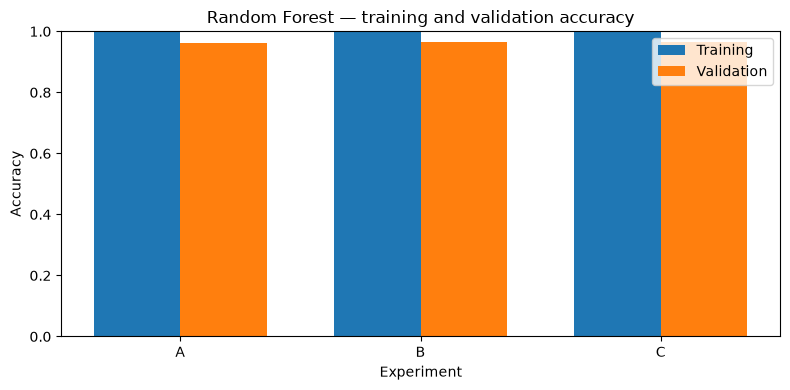

Selected configuration: {'name': 'C', 'n_estimators': 100, 'max_depth': None}
Validation accuracy: 0.9665
Saved compressed model: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1/models/rf_final.joblib


In [5]:
positions = np.arange(len(results))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(positions - 0.18, results['train_accuracy'], width=0.36, label='Training')
ax.bar(positions + 0.18, results['val_accuracy'], width=0.36, label='Validation')
ax.set_xticks(positions, results['name'])
ax.set_xlabel('Experiment')
ax.set_ylabel('Accuracy')
ax.set_ylim(0, 1)
ax.set_title('Random Forest — training and validation accuracy')
ax.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR / 'experiment_accuracies.png', dpi=150)
plt.show()  # display it

# Rank original configuration dictionaries so unlimited depth stays None rather than NaN.
score_by_name = {row['name']: row['val_accuracy'] for row in trial_results}
selected_config = sorted(
    EXPERIMENTS,
    key=lambda config: (-score_by_name[config['name']], config['n_estimators'],
                        float('inf') if config['max_depth'] is None else config['max_depth'],
                        config['name']),
)[0]
winner = next(row for row in trial_results if row['name'] == selected_config['name'])
best_rf = trial_models[selected_config['name']]
FINAL_PATH = MODEL_DIR / 'rf_final.joblib'
joblib.dump(best_rf, FINAL_PATH, compress=3)
print('Selected configuration:', selected_config)
print('Validation accuracy:', winner['val_accuracy'])
print('Saved compressed model:', FINAL_PATH)


## 4. Test the saved final forest

Only the validation-selected forest is evaluated on the test set. Export accuracy, macro precision/recall/F1, per-digit metrics, confusion matrix, and misclassified examples.

Time loading separately and warm up on validation data before timing predictions for 10,000 test images. This batch time is not single-drawing app latency. All cores are enabled for this training/evaluation run; the app's settings and hardware must be measured separately.


In [6]:
load_start = time.perf_counter()
rf_loaded = joblib.load(FINAL_PATH)
load_seconds = time.perf_counter() - load_start

# Warm up using validation data, leaving test evaluation to the next prediction.
_ = rf_loaded.predict_proba(X_val[:1])
start = time.perf_counter()
test_probs = rf_loaded.predict_proba(X_test)
inference_seconds = time.perf_counter() - start
assert test_probs.shape == (10000, 10)
assert np.isfinite(test_probs).all()
assert np.allclose(test_probs.sum(axis=1), 1.0, atol=1e-5)
test_pred = rf_loaded.classes_[np.argmax(test_probs, axis=1)]
test_accuracy = float(accuracy_score(y_test, test_pred))
macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    y_test, test_pred, average='macro', zero_division=0,
)
# Predictive cross-entropy excludes any L2 weight penalty.
true_class_probs = test_probs[np.arange(len(y_test)), y_test]
test_crossentropy = float(-np.log(np.clip(true_class_probs, 1e-7, 1.0)).mean())
report = classification_report(y_test, test_pred, labels=list(range(10)), output_dict=True, zero_division=0)
cm = confusion_matrix(y_test, test_pred, labels=list(range(10)))

print(f'Test accuracy: {test_accuracy:.4%}')
print(f'Macro F1: {macro_f1:.4f}')
print(f'Predictive cross-entropy: {test_crossentropy:.4f}')
print(f'Model size: {FINAL_PATH.stat().st_size / (1024 ** 2):.2f} MiB')
print(f'Loading: {load_seconds:.2f}s; 10,000 predictions after warm-up: {inference_seconds:.2f}s')
print(classification_report(y_test, test_pred, labels=list(range(10)), digits=4, zero_division=0))
pd.DataFrame(report).T.to_csv(RESULT_DIR / 'classification_report.csv')
pd.DataFrame(cm, index=range(10), columns=range(10)).to_csv(RESULT_DIR / 'confusion_matrix.csv')


Test accuracy: 96.9500%
Macro F1: 0.9693
Predictive cross-entropy: 0.2557
Model size: 18.94 MiB
Loading: 1.64s; 10,000 predictions after warm-up: 0.12s
              precision    recall  f1-score   support

           0     0.9739    0.9898    0.9818       980
           1     0.9886    0.9903    0.9894      1135
           2     0.9587    0.9671    0.9629      1032
           3     0.9549    0.9634    0.9591      1010
           4     0.9745    0.9745    0.9745       982
           5     0.9795    0.9630    0.9712       892
           6     0.9730    0.9781    0.9755       958
           7     0.9715    0.9621    0.9668      1028
           8     0.9617    0.9538    0.9577       974
           9     0.9580    0.9504    0.9542      1009

    accuracy                         0.9695     10000
   macro avg     0.9694    0.9692    0.9693     10000
weighted avg     0.9695    0.9695    0.9695     10000



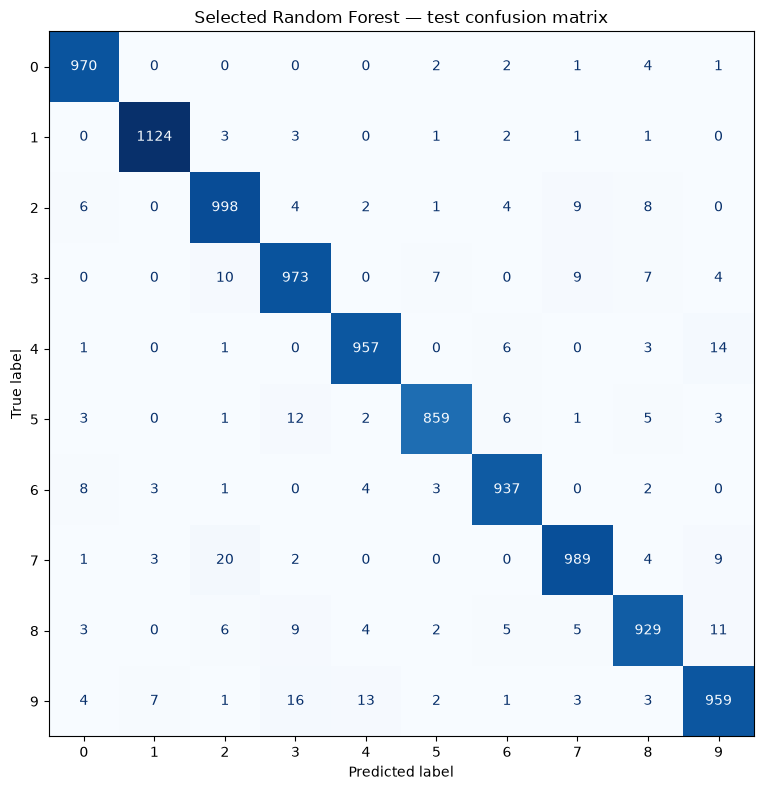

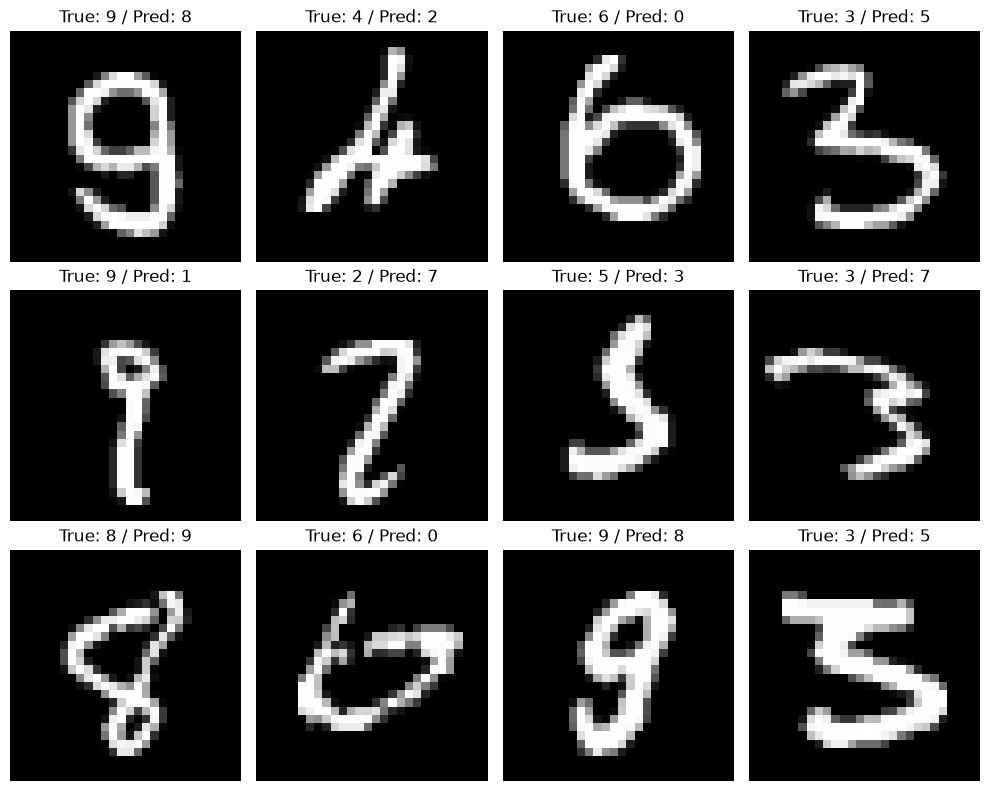

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Selected Random Forest — test confusion matrix')
fig.tight_layout()
fig.savefig(RESULT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()  # display it

wrong = np.flatnonzero(test_pred != y_test)[:12]
if len(wrong):
    fig, axes = plt.subplots(3, 4, figsize=(10, 8))
    for ax in axes.flat:
        ax.axis('off')
    for ax, index in zip(axes.flat, wrong):
        ax.imshow(X_test_raw[index], cmap='gray')
        ax.set_title(f'True: {y_test[index]} / Pred: {test_pred[index]}')
    fig.tight_layout()
    fig.savefig(RESULT_DIR / 'misclassified_examples.png', dpi=150)
    plt.show()  # display it
else:
    print('No test errors in this run.')


## 5. Verify reload and record the model contract

Compare validation predictions before/after serialization and verify that the classifier expects 784 features and ten classes. Record tree/node counts as structural complexity; they are not comparable to neural-network parameter counts as identical units. Keep the package versions used to train this joblib model for deployment.


In [8]:
before_reload = best_rf.predict_proba(X_val[:32])
after_reload = rf_loaded.predict_proba(X_val[:32])
np.testing.assert_allclose(before_reload, after_reload, rtol=1e-7, atol=1e-8)
assert rf_loaded.n_features_in_ == 784
assert np.array_equal(rf_loaded.classes_, np.arange(10))
print('Reload check passed; input (N,784), classes 0–9.')

metrics = {
    'model': 'Random Forest',
    'selected_trial': str(winner['name']),
    'best_epoch': None,
    'validation_accuracy': float(winner['val_accuracy']),
    'test_accuracy': test_accuracy,
    'test_predictive_crossentropy': test_crossentropy,
    'macro_precision': float(macro_precision),
    'macro_recall': float(macro_recall),
    'macro_f1': float(macro_f1),
    'parameters': None,
    'n_estimators': int(rf_loaded.n_estimators),
    'tree_nodes': int(winner['tree_nodes']),
    'observed_max_depth': int(winner['observed_max_depth']),
    'selected_trial_train_seconds': float(winner['train_seconds']),
    'total_search_train_seconds': float(results['train_seconds'].sum()),
    'load_seconds': float(load_seconds),
    'test_inference_seconds_10000_after_warmup': float(inference_seconds),
    'file_size_mib': FINAL_PATH.stat().st_size / (1024 ** 2),
}
metadata = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'dataset': 'MNIST',
    'split': {'train': 50000, 'validation': 10000, 'test': 10000,
              'random_state': SEED, 'stratify': True},
    'preprocessing': {'input_shape': [784], 'dtype': 'float32',
                      'normalization': 'raw pixel / 255.0',
                      'polarity': 'bright digit on dark background',
                      'labels': 'integer digits 0-9'},
    'selection': 'Highest validation accuracy; tie: fewer trees, shallower depth limit, trial name',
    'hyperparameters': selected_config,
    'training': {'seed': SEED, 'n_jobs': -1, 'device': 'CPU'},
    'environment': environment,
    'metrics': metrics,
}
(MODEL_DIR / 'rf_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
(RESULT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
pd.DataFrame([metrics]).to_csv(RESULT_DIR / 'comparison_row.csv', index=False)
(RESULT_DIR / 'environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print(json.dumps(metrics, indent=2))

# Release the non-winning forests; keep only the loaded final model for inspection.
del trial_models, best_rf


Reload check passed; input (N,784), classes 0–9.
{
  "model": "Random Forest",
  "selected_trial": "C",
  "best_epoch": null,
  "validation_accuracy": 0.9665,
  "test_accuracy": 0.9695,
  "test_predictive_crossentropy": 0.255669646265041,
  "macro_precision": 0.9694283977958114,
  "macro_recall": 0.9692457467286287,
  "macro_f1": 0.9693137623443617,
  "parameters": null,
  "n_estimators": 100,
  "tree_nodes": 862140,
  "observed_max_depth": 41,
  "selected_trial_train_seconds": 4.331090790999951,
  "total_search_train_seconds": 10.744670792999841,
  "load_seconds": 1.6354169080000247,
  "test_inference_seconds_10000_after_warmup": 0.1222214869999334,
  "file_size_mib": 18.941702842712402
}


## 6. Conclusions and app contract

Use the tuning table to explain whether more trees and unlimited depth improved validation accuracy. Discuss the training/validation gap, tree/node counts, fit time, compressed artifact size, and per-digit mistakes. Small validation differences should not be overstated. The test set describes the chosen model; it is not a tuning source.

Compare the three models using the shared report. RF trees/node counts and neural-network parameter counts are different structural measures. CPU/GPU and timing differences must be documented. Do not fill the report with original scores as though they were generated by this run.

Load `models/rf_final.joblib` with `joblib.load(path)` in a matching scikit-learn environment. Supply one normalized bright-on-dark digit as `float32` shape **(1,784)**. Use `predict` for the digit or `predict_proba` for class scores. Map probability columns using `model.classes_`. Forest probability scores need not be calibrated confidence estimates.

Prepare a drawn digit with grayscale conversion, content crop, aspect-ratio-preserving resize, centering in 28×28 pixels, and blank-input rejection. Avoid dividing normalized pixels by 255 a second time. The drawing application remains the next implementation stage; picture upload comes after the core app and documentation.


## 7. Optional Colab download

The next cell creates a ZIP containing the final model, metadata, and this run's result files (excluding experiment checkpoints). In Colab it downloads the ZIP. Outside Colab it prints its location. Keep only the three final models in the eventual deployment repository; intermediate tuning checkpoints are not required app assets.


In [9]:
import zipfile

archive_path = PROJECT_ROOT / 'rf_deliverables.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in [FINAL_PATH, MODEL_DIR / 'rf_metadata.json', *sorted(RESULT_DIR.glob('*'))]:
        if path.is_file():
            archive.write(path, arcname=str(path.relative_to(PROJECT_ROOT)))
print('Deliverables ZIP:', archive_path)
try:
    from google.colab import files
except ImportError:
    print('Local environment: retrieve the ZIP from the path above.')
else:
    files.download(str(archive_path))


Deliverables ZIP: /mnt/c/Users/omarh/OneDrive/Desktop/Uni/Professional Training In Ai Ii/Assignments/Assignment1/rf_deliverables.zip
Local environment: retrieve the ZIP from the path above.


## Original code comments retained for study

These verbatim excerpts preserve comments attached to code that changed during correction. They are historical study material; run the corrected executable cells above. NumPy-only seeding does not seed all TensorFlow randomness, and MNIST may download on first use.

Original code cell 10:

```python
plt.imshow(X_train_full[2005], cmap="gray") # imshow = "image show"; cmap="gray" draws it in black-and-white
plt.title("Label: " + str(y_train_full[2005]))  # put the label above the picture
plt.axis("off")                          # hide the x/y axis numbers
```

Original code cell 12:

```python
# Split the 60,000 training images into 50,000 train + 10,000 validation
    test_size=10000,              # how many go into the second part (validation)
    random_state=42,              # fixed seed -> same shuffle every time, for everyone
    stratify=y_train_full         # keep the same share of each digit in both parts
```

Original code cell 26:

```python
from sklearn.metrics import accuracy_score               # share of correct predictions
```

Original code cell 27:

```python
# 1. Create the forest with experiment A's settings
    n_estimators=50,     # number of trees that vote
    max_depth=20,        # each tree may ask at most 20 questions in a row
    random_state=42,     # fixed seed so results repeat
    n_jobs=-1            # use all CPU cores to train faster (does not change results)
```

Original code cell 29:

```python
# 2. Train it, and time it
start = time.time()                  # note the clock before training
rf_a.fit(X_train_flat, y_train)      # builds its trees from the training images and labels.
train_time = time.time() - start     # time after minus time before
```

Original code cell 31:

```python
# 3. Predict the validation images and score them
val_pred = rf_a.predict(X_val_flat)              #  gives one guess per image. The forest runs each image through all 50 trees and takes the majority vote.
val_acc = accuracy_score(y_val, val_pred)        # compare guesses with true labels
```

Original code cell 33:

```python
        max_depth=depth,        # None means "no limit"
```

Original code cell 36:

```python
import os        # os lets us ask the computer about files
# Save each experiment to a file, then read how big the file is (in MB)
    joblib.dump(model, filename)                      # write the model to disk
    size_mb = os.path.getsize(filename) / (1024 * 1024)   # bytes -> megabytes
```

Original code cell 37:

```python
    joblib.dump(model, filename, compress=3)   # compress=3: moderate compression level (0 = none, 9 = max)
```

Original code cell 38:

```python
# 1. Save the chosen model (compressed) as the final file the app will load
# 2. Reload it from disk, as the app will do later
# 3. Score the reloaded model on the TEST set (first time we touch it)
```
